In [2]:
import abc

import cv2
import numpy as np
import onnxruntime as ort
import matplotlib.pyplot as plt

In [3]:
class YOLOv8:
    """YOLOv8 object detection model class for handling inference and visualization."""

    def __init__(self, onnx_model, input_image, confidence_thres, iou_thres, classes):
        """
        Initializes an instance of the YOLOv8 class.

        Args:
            onnx_model: Path to the ONNX model.
            input_image: Path to the input image.
            confidence_thres: Confidence threshold for filtering detections.
            iou_thres: IoU (Intersection over Union) threshold for non-maximum suppression.
        """
        self.onnx_model = onnx_model
        self.input_image = input_image
        self.confidence_thres = confidence_thres
        self.iou_thres = iou_thres

        # Load the class names from the COCO dataset
        self.classes = classes

        # Generate a color palette for the classes
        self.color_palette = np.random.uniform(0, 255, size=(len(self.classes), 3))

    def draw_detections(self, img, box, score, class_id):
        """
        Draws bounding boxes and labels on the input image based on the detected objects.

        Args:
            img: The input image to draw detections on.
            box: Detected bounding box.
            score: Corresponding detection score.
            class_id: Class ID for the detected object.

        Returns:
            None
        """

        # Extract the coordinates of the bounding box
        x1, y1, w, h = box

        # Retrieve the color for the class ID
        color = self.color_palette[class_id]

        # Draw the bounding box on the image
        cv2.rectangle(img, (int(x1), int(y1)), (int(x1 + w), int(y1 + h)), color, 2)

        # Create the label text with class name and score
        label = f"{self.classes[class_id]}: {score:.2f}"

        # Calculate the dimensions of the label text
        (label_width, label_height), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)

        # Calculate the position of the label text
        label_x = x1
        label_y = y1 - 10 if y1 - 10 > label_height else y1 + 10

        # Draw a filled rectangle as the background for the label text
        cv2.rectangle(
            img, (label_x, label_y - label_height), (label_x + label_width, label_y + label_height), color, cv2.FILLED
        )

        # Draw the label text on the image
        cv2.putText(img, label, (label_x, label_y), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1, cv2.LINE_AA)

    def preprocess(self):
        """
        Preprocesses the input image before performing inference.

        Returns:
            image_data: Preprocessed image data ready for inference.
        """
        # Read the input image using OpenCV
        self.img = cv2.imread(self.input_image)

        # Get the height and width of the input image
        self.img_height, self.img_width = self.img.shape[:2]

        # Convert the image color space from BGR to RGB
        img = cv2.cvtColor(self.img, cv2.COLOR_BGR2RGB)

        # Resize the image to match the input shape
        img = cv2.resize(img, (self.input_width, self.input_height))

        # Normalize the image data by dividing it by 255.0
        image_data = np.array(img) / 255.0

        # Transpose the image to have the channel dimension as the first dimension
        image_data = np.transpose(image_data, (2, 0, 1))  # Channel first

        # Expand the dimensions of the image data to match the expected input shape
        image_data = np.expand_dims(image_data, axis=0).astype(np.float32)

        # Return the preprocessed image data
        return image_data

    def postprocess(self, input_image, output):
        """
        Performs post-processing on the model's output to extract bounding boxes, scores, and class IDs.

        Args:
            input_image (numpy.ndarray): The input image.
            output (numpy.ndarray): The output of the model.

        Returns:
            numpy.ndarray: The input image with detections drawn on it.
        """

        # Transpose and squeeze the output to match the expected shape
        outputs = np.transpose(np.squeeze(output[0]))

        # Get the number of rows in the outputs array
        rows = outputs.shape[0]

        # Lists to store the bounding boxes, scores, and class IDs of the detections
        boxes = []
        scores = []
        class_ids = []

        # Calculate the scaling factors for the bounding box coordinates
        x_factor = self.img_width / self.input_width
        y_factor = self.img_height / self.input_height

        # Iterate over each row in the outputs array
        for i in range(rows):
            # Extract the class scores from the current row
            classes_scores = outputs[i][4:]

            # Find the maximum score among the class scores
            max_score = np.amax(classes_scores)

            # If the maximum score is above the confidence threshold
            if max_score >= self.confidence_thres:
                # Get the class ID with the highest score
                class_id = np.argmax(classes_scores)

                # Extract the bounding box coordinates from the current row
                x, y, w, h = outputs[i][0], outputs[i][1], outputs[i][2], outputs[i][3]

                # Calculate the scaled coordinates of the bounding box
                left = int((x - w / 2) * x_factor)
                top = int((y - h / 2) * y_factor)
                width = int(w * x_factor)
                height = int(h * y_factor)

                # Add the class ID, score, and box coordinates to the respective lists
                class_ids.append(class_id)
                scores.append(max_score)
                boxes.append([left, top, width, height])

        # Apply non-maximum suppression to filter out overlapping bounding boxes
        indices = cv2.dnn.NMSBoxes(boxes, scores, self.confidence_thres, self.iou_thres)

        # Iterate over the selected indices after non-maximum suppression
        for i in indices:
            # Get the box, score, and class ID corresponding to the index
            box = boxes[i]
            score = scores[i]
            class_id = class_ids[i]

            # Draw the detection on the input image
            self.draw_detections(input_image, box, score, class_id)

        # Return the modified input image
        return input_image

    def main(self):
        """
        Performs inference using an ONNX model and returns the output image with drawn detections.

        Returns:
            output_img: The output image with drawn detections.
        """
        # Create an inference session using the ONNX model and specify execution providers
        session = ort.InferenceSession(self.onnx_model, providers=["CPUExecutionProvider"])

        # Get the model inputs
        model_inputs = session.get_inputs()

        # Store the shape of the input for later use
        input_shape = model_inputs[0].shape
        self.input_width = input_shape[2]
        self.input_height = input_shape[3]

        # Preprocess the image data
        img_data = self.preprocess()

        # Run inference using the preprocessed image data
        outputs = session.run(None, {model_inputs[0].name: img_data})

        # Perform post-processing on the outputs to obtain output image.
        return self.postprocess(self.img, outputs)  # output image

In [4]:
detection = YOLOv8(
    "../yolo_artifacts/baseline_ultralytics/weights/best.onnx",
    "../theodore_yolo/test/0000275.jpg",
    0.2,
    0.7,
    {
        0: 'person',
        1: 'chair',
        2: 'table',
        3: 'armchair',
        4: 'tv',
        5: 'wheeled walker'
    }
)

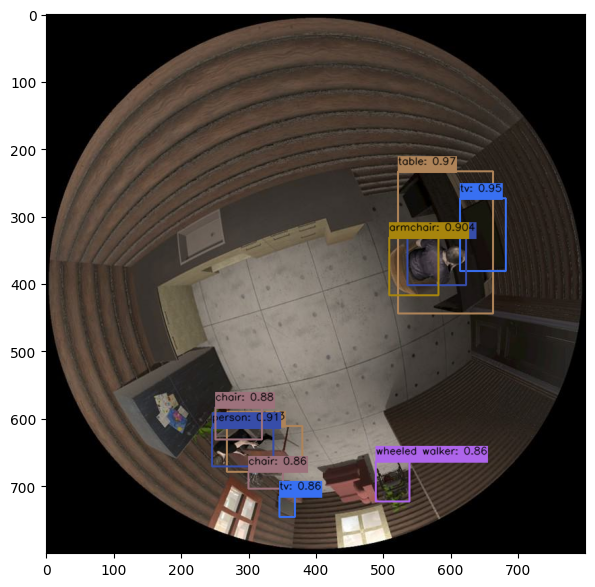

In [5]:
# Perform object detection and obtain the output image
output_image = detection.main()
plt.figure(figsize=(7, 7))
plt.imshow(cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB))

In [6]:
MEAN = np.array([0.485, 0.456, 0.406])
STD = np.array([0.229, 0.224, 0.225])

def preprocess(x: np.ndarray, img_size = 128) -> np.ndarray:
    x = cv2.resize(x, (img_size, img_size), interpolation=cv2.INTER_CUBIC)
    x = x / 255.0
    x = (x - MEAN) / STD
    return np.transpose(x, (2, 0, 1))[None].astype(np.float32)

[1, 3, 128, 128]


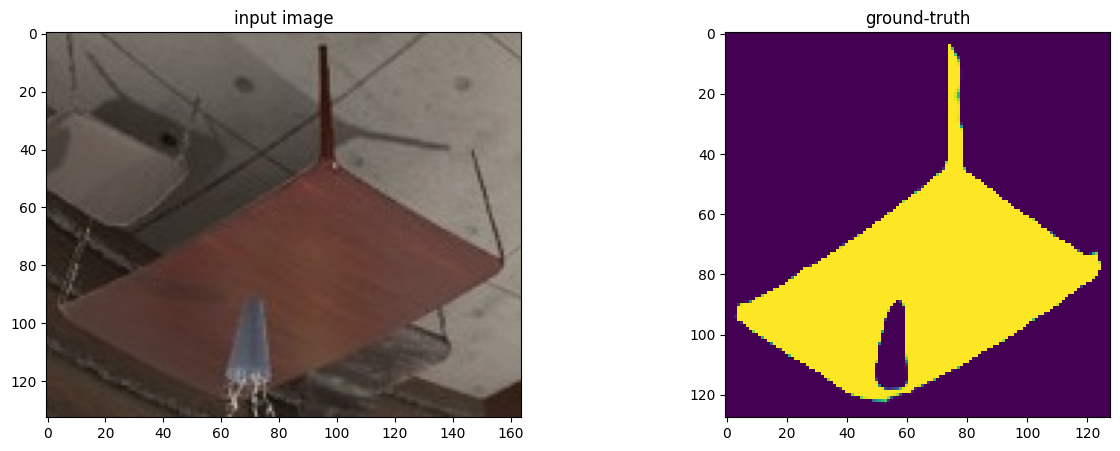

In [7]:
# Create an inference session using the ONNX model and specify execution providers
session = ort.InferenceSession(
    "../fpn/runs/baseline_fpn_timm-mobilenetv3_small_100_schedule_25_upd_early_stopping/best.onnx",
    providers=["CPUExecutionProvider"]
)

# Get the model inputs
model_inputs = session.get_inputs()

input_img = cv2.cvtColor(cv2.imread("../theodore_unet/imgs/0000251_0.jpg"), cv2.COLOR_BGR2RGB)

# Store the shape of the input for later use
input_shape = model_inputs[0].shape
print(input_shape)
# self.input_width = input_shape[2]
# self.input_height = input_shape[3]

# Preprocess the image data
img_data = preprocess(input_img, input_shape[2])

# Run inference using the preprocessed image data
outputs = session.run(None, {model_inputs[0].name: img_data})

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.title("input image")
plt.imshow(input_img)

plt.subplot(1, 2, 2)
plt.title("ground-truth")
plt.imshow(outputs[0][0, 0])

In [8]:
# Load the ONNX model
net = cv2.dnn.readNetFromONNX("../yolo_artifacts/baseline_ultralytics/weights/best.onnx")

In [9]:
CLASSES = {
        0: 'person',
        1: 'chair',
        2: 'table',
        3: 'armchair',
        4: 'tv',
        5: 'wheeled walker'
    }
colors = np.random.uniform(0, 255, size=(len(CLASSES), 3))

def draw_bounding_box(img, class_id, confidence, x, y, x_plus_w, y_plus_h):
    """
    Draws bounding boxes on the input image based on the provided arguments.

    Args:
        img (numpy.ndarray): The input image to draw the bounding box on.
        class_id (int): Class ID of the detected object.
        confidence (float): Confidence score of the detected object.
        x (int): X-coordinate of the top-left corner of the bounding box.
        y (int): Y-coordinate of the top-left corner of the bounding box.
        x_plus_w (int): X-coordinate of the bottom-right corner of the bounding box.
        y_plus_h (int): Y-coordinate of the bottom-right corner of the bounding box.
    """
    label = f"{CLASSES[class_id]} ({confidence:.2f})"
    color = colors[class_id]
    cv2.rectangle(img, (x, y), (x_plus_w, y_plus_h), color, 2)
    cv2.putText(img, label, (x - 10, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

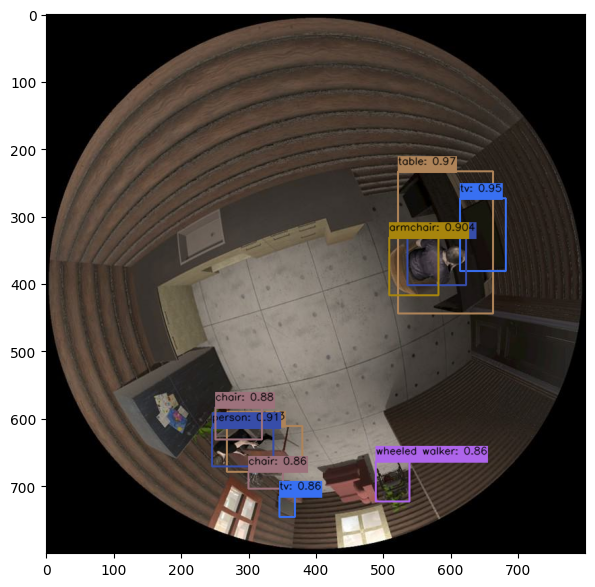

In [10]:
onnx_model = "../yolo_artifacts/baseline_ultralytics/weights/best.onnx"
input_image = "../theodore_yolo/test/0000275.jpg"

# Load the ONNX model
model: cv2.dnn.Net = cv2.dnn.readNetFromONNX(onnx_model)

# Read the input image
original_image: np.ndarray = cv2.imread(input_image)
[height, width, _] = original_image.shape

# Prepare a square image for inference
length = max((height, width))
image = np.zeros((length, length, 3), np.uint8)
image[0:height, 0:width] = original_image

# Calculate scale factor
scale = length / 640

# Preprocess the image and prepare blob for model
blob = cv2.dnn.blobFromImage(image, scalefactor=1 / 255, size=(640, 640), swapRB=True)
model.setInput(blob)

# Perform inference
outputs = model.forward()

# Prepare output array
outputs = np.array([cv2.transpose(outputs[0])])
rows = outputs.shape[1]

boxes = []
scores = []
class_ids = []

# Iterate through output to collect bounding boxes, confidence scores, and class IDs
for i in range(rows):
    classes_scores = outputs[0][i][4:]
    (minScore, maxScore, minClassLoc, (x, maxClassIndex)) = cv2.minMaxLoc(classes_scores)
    if maxScore >= 0.25:
        box = [
            outputs[0][i][0] - (0.5 * outputs[0][i][2]),
            outputs[0][i][1] - (0.5 * outputs[0][i][3]),
            outputs[0][i][2],
            outputs[0][i][3],
        ]
        boxes.append(box)
        scores.append(maxScore)
        class_ids.append(maxClassIndex)

# Apply NMS (Non-maximum suppression)
result_boxes = cv2.dnn.NMSBoxes(boxes, scores, 0.25, 0.45, 0.5)

detections = []

# Iterate through NMS results to draw bounding boxes and labels
for i in range(len(result_boxes)):
    index = result_boxes[i]
    box = boxes[index]
    detection = {
        "class_id": class_ids[index],
        "class_name": CLASSES[class_ids[index]],
        "confidence": scores[index],
        "box": box,
        "scale": scale,
    }
    detections.append(detection)
    draw_bounding_box(
        original_image,
        class_ids[index],
        scores[index],
        round(box[0] * scale),
        round(box[1] * scale),
        round((box[0] + box[2]) * scale),
        round((box[1] + box[3]) * scale),
    )

# Display the image with bounding boxes
plt.figure(figsize=(7, 7))
plt.imshow(cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB))

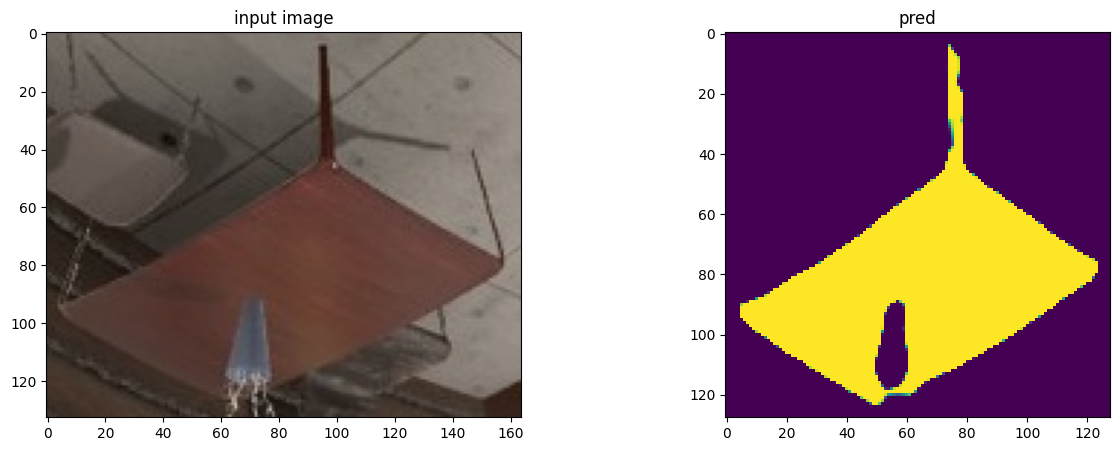

In [11]:
onnx_model = "../fpn/runs/pan_mobilenet_v2_schedule_25_upd_early_stopping/best_upd.onnx"
input_image = "../theodore_unet/imgs/0000251_0.jpg"

# Load the ONNX model
model = cv2.dnn.readNetFromONNX(onnx_model)

input_img = cv2.cvtColor(cv2.imread("../theodore_unet/imgs/0000251_0.jpg"), cv2.COLOR_BGR2RGB)
blob = preprocess(input_img, 128)

# blob = cv2.dnn.blobFromImage(input_img, scalefactor=1 / 255, size=(128, 128), swapRB=True)
model.setInput(blob)

# Perform inference
outputs = model.forward()

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.title("input image")
plt.imshow(input_img)

plt.subplot(1, 2, 2)
plt.title("pred")
plt.imshow(outputs[0][0])

In [12]:
class BaseModel(abc.ABC):
    def __init__(self,  onnx_model, img_size, **kwargs):
        self.model = cv2.dnn.readNetFromONNX(onnx_model)
        self.img_size = img_size
    
    @abc.abstractmethod
    def preprocessing(self, img):
        pass
    
    @abc.abstractmethod
    def postprocessing(self, outputs):
        pass
    
    def detect(self, img):
        blob = self.preprocessing(img)

        # Perform inference
        model.setInput(blob)
        outputs = model.forward()

        return self.postprocessing(outputs)


class Detector(BaseModel):
    pass